# Examination of a 1D Powered Rocket Ascent w/ Drag

## 1. Governing Initial Value Problem (IVP)

To characterize aerodynamic drag losses on a sounding rocket during powered vertical flight, we model the rocket as a 1D point mass ascending through an exponential atmosphere under constant motor thrust $T$ and constant gravitational acceleration $g_0$. 

### State Vector & Coupled ODE System
Let $h(t)$ be the altitude, $v(t)$ be the vertical velocity, $m(t)$ be the instantaneous rocket mass, and $\Delta v_{\text{drag}}(t)$ be the cumulative velocity loss due to aerodynamic drag. Over the powered burn duration $t \in [0, t_b]$, the state vector $y(t)$ and its time derivative $\dot{y} = f(t, y)$ are governed by the non-autonomous nonlinear system:

$$y(t) = \begin{bmatrix} h(t) \\ v(t) \\ m(t) \\ \Delta v_{\text{drag}}(t) \end{bmatrix}, \qquad \frac{dy}{dt} = f(t, y) = \begin{bmatrix} v \\[6pt] \dfrac{T}{m} - g_0 - \dfrac{\rho(h) C_D S}{2m} v|v| \\[8pt] -\dfrac{T}{I_{sp} g_0} \\[8pt] \dfrac{\rho(h) C_D S}{2m} v^2 \end{bmatrix}$$

### Initial Conditions & Time Domain
Assuming the rocket launches vertically from rest at sea level at $t = 0$:

$$h(0) = 0\text{ m}, \qquad v(0) = 0\text{ m/s}, \qquad m(0) = m_0, \qquad \Delta v_{\text{drag}}(0) = 0\text{ m/s}$$

The integration domain spans the powered burn phase $t \in [0, t_b]$, where burnout occurs when all propellant is expended ($m(t_b) = m_{\text{dry}}$):

$$t_b = \frac{(m_0 - m_{\text{dry}}) I_{sp} g_0}{T}$$

### Supporting Models
* **Exponential Atmosphere:** Air density decays exponentially with altitude $h$ according to scale height $H$:
  $$\rho(h) = \rho_0 e^{-h/H}$$
* **Cross-Sectional Reference Area:** For a cylindrical rocket body of diameter $d$:
  $$S = \frac{\pi d^2}{4}$$
* **Propellant Mass Flow Rate:** Constant mass consumption rate during motor burn:
  $$\dot{m} = -\frac{T}{I_{sp} g_0}$$

---

## 2. Nominal System Parameters

| Parameter | Symbol | Value | Units |
| :--- | :---: | :---: | :---: |
| Gravitational Acceleration | $g$ | $9.81$ | $\text{m/s}^2$ |
| Sea-Level Air Density | $\rho_0$ | $1.225$ | $\text{kg/m}^3$ |
| Atmospheric Scale Height | $H$ | $8500$ | $\text{m}$ |
| Liftoff (Wet) Mass | $m_0$ | $50.0$ | $\text{kg}$ |
| Burnout (Dry) Mass | $m_{\text{dry}}$ | $20.0$ | $\text{kg}$ |
| Motor Thrust | $T$ | $3000.0$ | $\text{N}$ |
| Specific Impulse | $I_{sp}$ | $230.0$ | $\text{s}$ |
| Rocket Body Diameter | $d$ | $0.15$ | $\text{m}$ |
| Reference Area | $S$ | $0.01767$ | $\text{m}^2$ |
| Drag Coefficient | $C_D$ | $0.4$ | — |
| Mass Flow Rate | $\dot{m}$ | $1.3296$ | $\text{kg/s}$ |
| Burnout Time | $t_b$ | $22.563$ | $\text{s}$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt


g = 9.81                        # Constant gravitational acceleration [m/s^2]
rho0 = 1.225                     # Sea-level air density [kg/m^3]
H = 8500.0                       # Atmospheric scale height [m]

m0 = 50.0                        # Liftoff mass [kg]
m_dry = 20.0                     # Burnout (dry) mass [kg]
T = 3000.0                       # Constant motor thrust [N]
Isp = 230.0                      # Specific impulse [s]
d = 0.15                         # Rocket body diameter [m]

# Derived parameters
S = np.pi * (d ** 2) / 4.0       # Cross-sectional reference area [m^2]
mdot = T / (Isp * g)            # Propellant mass consumption rate [kg/s]
t_b = (m0 - m_dry) / mdot        # Burnout time [s]


def rocket_burn_rhs(t, y, C_D):
    """
    Evaluates the RHS f(t, y) for 1D powered vertical ascent on t in [0, t_b].
    State vector: y = [h, v, m, dv_drag]
    """
    h, v, m, _ = y

    rho_local = rho0 * np.exp(-h / H)
    drag_factor = (rho_local * C_D * S) / (2.0 * m)

    h_dot = v
    v_dot = (T / m) - g - drag_factor * v * abs(v)
    m_dot = -mdot
    dv_drag_dot = drag_factor * (v ** 2)

    return np.array([h_dot, v_dot, m_dot, dv_drag_dot], dtype=float)


def rk4_step(f, t, y, dt, C_D):
    """Advances state y from t_k to t_{k+1} = t_k + dt using classical RK4."""
    k1 = f(t, y, C_D)
    k2 = f(t + 0.5 * dt, y + 0.5 * dt * k1, C_D)
    k3 = f(t + 0.5 * dt, y + 0.5 * dt * k2, C_D)
    k4 = f(t + dt, y + dt * k3, C_D)
    return y + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)


def solve_burn_ivp(n_steps, C_D):
    """
    Time-marches the powered ascent IVP from t = 0 to t = t_b using n_steps.
    Returns time array t, state history array y, and step size dt.
    """
    dt = t_b / n_steps
    t = np.linspace(0.0, t_b, n_steps + 1)
    y = np.zeros((n_steps + 1, 4), dtype=float)

    # Initial conditions: h(0) = 0, v(0) = 0, m(0) = m0, dv_drag(0) = 0
    y[0] = np.array([0.0, 0.0, m0, 0.0])

    for k in range(n_steps):
        y[k + 1] = rk4_step(rocket_burn_rhs, t[k], y[k], dt, C_D)

    return t, y, dt

1. Analytical Special-Case Verification (C_D = 0)
Exact Burnout Altitude h(t_b) : 17313.581907 m
Exact Burnout Velocity v(t_b) : 1846.083748 m/s
Convergence Rate vs. Exact    : p = 3.9969

2. Full Nonlinear Model Convergence & Step Size Study (C_D = 0.4)
     N |    dt [s] |  Rel Err h(tb) |  Rel Err v(tb) | Rel Err dv_drag
--------------------------------------------------------------------
    10 |   2.25630 |     9.3646e-06 |     8.5937e-06 |      1.2165e-05
    20 |   1.12815 |     6.0091e-07 |     5.8288e-07 |      8.4156e-07
    40 |   0.56408 |     3.7793e-08 |     3.7470e-08 |      5.4470e-08
    80 |   0.28204 |     2.3675e-09 |     2.3656e-09 |      3.4602e-09
   160 |   0.14102 |     1.5000e-10 |     1.4573e-10 |      2.2561e-10
   320 |   0.07051 |     1.1362e-11 |     6.2792e-12 |      2.2157e-11
   640 |   0.03525 |     2.6965e-12 |     2.4569e-12 |      9.4025e-12
  1280 |   0.01763 |     2.1548e-12 |     3.0023e-12 |      8.6017e-12

Observed Full-Model Convergence Rate

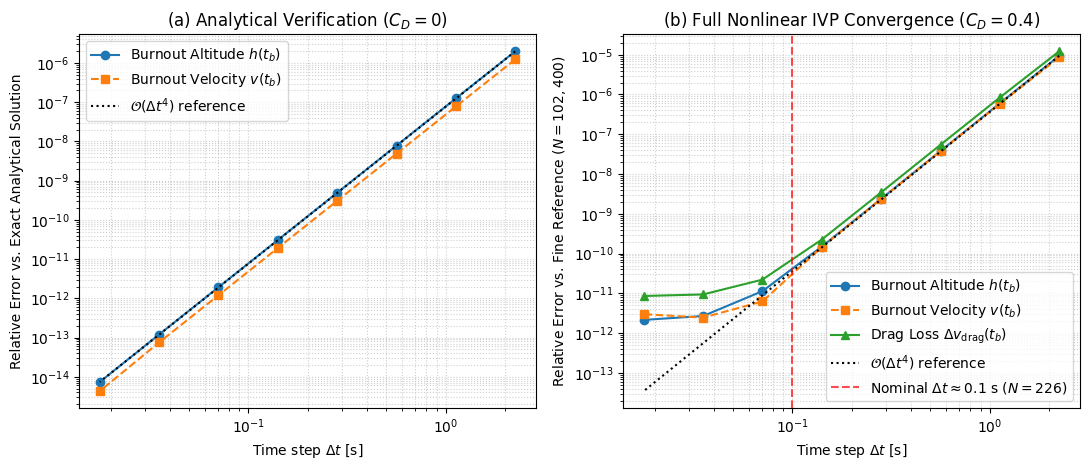

In [8]:
def exact_drag_free_solution(t):
    """Exact closed-form solution at time t for the drag-free limit (C_D = 0)."""
    ve = Isp * g
    m_t = m0 - mdot * t

    v_exact = ve * np.log(m0 / m_t) - g * t
    h_exact = ve * (t + (m_t / mdot) * np.log(m_t / m0)) - 0.5 * g * (t ** 2)
    return h_exact, v_exact


n_list = np.array([10, 20, 40, 80, 160, 320, 640, 1280])
dt_arr = t_b / n_list

# -------------------------------------------------------------------------
# PART 1: Verification against Exact Analytical Solution (C_D = 0)
# -------------------------------------------------------------------------
h_ex_tb, v_ex_tb = exact_drag_free_solution(t_b)
err_h_ideal = np.zeros(len(n_list))
err_v_ideal = np.zeros(len(n_list))

for i, n in enumerate(n_list):
    _, y, _ = solve_burn_ivp(n, C_D=0.0)
    err_h_ideal[i] = abs(y[-1, 0] - h_ex_tb) / abs(h_ex_tb)
    err_v_ideal[i] = abs(y[-1, 1] - v_ex_tb) / abs(v_ex_tb)

rate_ideal = np.polyfit(np.log10(dt_arr[:6]), np.log10(err_h_ideal[:6]), 1)[0]
print("1. Analytical Special-Case Verification (C_D = 0)")
print(f"Exact Burnout Altitude h(t_b) : {h_ex_tb:.6f} m")
print(f"Exact Burnout Velocity v(t_b) : {v_ex_tb:.6f} m/s")
print(f"Convergence Rate vs. Exact    : p = {rate_ideal:.4f}\n")

# -------------------------------------------------------------------------
# PART 2: Full Nonlinear Model Convergence & Step Size Selection (C_D = 0.4)
# -------------------------------------------------------------------------
_, y_ref, _ = solve_burn_ivp(n_steps=102400, C_D=0.4)
h_ref, v_ref, dv_ref = y_ref[-1, 0], y_ref[-1, 1], y_ref[-1, 3]

err_h_drag = np.zeros(len(n_list))
err_v_drag = np.zeros(len(n_list))
err_dv_drag = np.zeros(len(n_list))

print("2. Full Nonlinear Model Convergence & Step Size Study (C_D = 0.4)")
print(f"{'N':>6} | {'dt [s]':>9} | {'Rel Err h(tb)':>14} | {'Rel Err v(tb)':>14} | {'Rel Err dv_drag':>15}")
print("-" * 68)

for i, n in enumerate(n_list):
    _, y, dt = solve_burn_ivp(n, C_D=0.4)
    err_h_drag[i] = abs(y[-1, 0] - h_ref) / abs(h_ref)
    err_v_drag[i] = abs(y[-1, 1] - v_ref) / abs(v_ref)
    err_dv_drag[i] = abs(y[-1, 3] - dv_ref) / abs(dv_ref)

    print(f"{n:6d} | {dt:9.5f} | {err_h_drag[i]:14.4e} | {err_v_drag[i]:14.4e} | {err_dv_drag[i]:15.4e}")

rate_drag = np.polyfit(np.log10(dt_arr[:6]), np.log10(err_h_drag[:6]), 1)[0]
print(f"\nObserved Full-Model Convergence Rate: p = {rate_drag:.4f}\n")

# -------------------------------------------------------------------------
# PART 3: Momentum Conservation Identity Check at Nominal Step (N = 226, dt ~ 0.1s)
# -------------------------------------------------------------------------
_, y_nom_0, _ = solve_burn_ivp(n_steps=226, C_D=0.0)
_, y_nom_d, _ = solve_burn_ivp(n_steps=226, C_D=0.4)
dv_by_subtraction = y_nom_0[-1, 1] - y_nom_d[-1, 1]
dv_by_direct_state = y_nom_d[-1, 3]

print("3. Integral Momentum Conservation Check (at dt ~ 0.1 s)")
print(f"Drag loss via state subtraction (v_CD0 - v_CD0.4) : {dv_by_subtraction:.10f} m/s")
print(f"Drag loss via 4th state integral (dv_drag)        : {dv_by_direct_state:.10f} m/s")
print(f"Discrepancy between methods                       : {abs(dv_by_subtraction - dv_by_direct_state):.3e} m/s")

# -------------------------------------------------------------------------
# PLOTTING
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))

# Left panel: Exact Analytical Verification (C_D = 0)
ax1.loglog(dt_arr, err_h_ideal, 'o-', label=r'Burnout Altitude $h(t_b)$')
ax1.loglog(dt_arr, err_v_ideal, 's--', label=r'Burnout Velocity $v(t_b)$')
ax1.loglog(dt_arr, err_h_ideal[0] * (dt_arr / dt_arr[0])**4, 'k:', label=r'$\mathcal{O}(\Delta t^4)$ reference')
ax1.set_xlabel(r'Time step $\Delta t$ [s]')
ax1.set_ylabel('Relative Error vs. Exact Analytical Solution')
ax1.set_title(r'(a) Analytical Verification ($C_D = 0$)')
ax1.grid(True, which="both", ls=":", alpha=0.6)
ax1.legend()

# Right panel: Full Nonlinear Drag Model Self-Convergence (C_D = 0.4)
ax2.loglog(dt_arr, err_h_drag, 'o-', label=r'Burnout Altitude $h(t_b)$')
ax2.loglog(dt_arr, err_v_drag, 's--', label=r'Burnout Velocity $v(t_b)$')
ax2.loglog(dt_arr, err_dv_drag, '^-', label=r'Drag Loss $\Delta v_{\mathrm{drag}}(t_b)$')
ax2.loglog(dt_arr, err_h_drag[0] * (dt_arr / dt_arr[0])**4, 'k:', label=r'$\mathcal{O}(\Delta t^4)$ reference')
ax2.axvline(t_b / 226, color='r', ls='--', alpha=0.7, label=r'Nominal $\Delta t \approx 0.1$ s ($N=226$)')
ax2.set_xlabel(r'Time step $\Delta t$ [s]')
ax2.set_ylabel('Relative Error vs. Fine Reference ($N=102,400$)')
ax2.set_title(r'(b) Full Nonlinear IVP Convergence ($C_D = 0.4$)')
ax2.grid(True, which="both", ls=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()